# Sleuth Demo

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sea
import jax
import jax.numpy as jnp
from glob import glob
from scipy.optimize import minimize
from astropy.io import fits
from astropy import wcs
from matplotlib.gridspec import GridSpec
import os
import pandas as pd
from eazy.templates import read_templates_file

from sleuth import Sleuth, Field, Galaxy
from sleuth.templates import Grism_template, TemplateLibrary, add_lines_to_template, line_dict, generate_1d_templates
from sleuth.blot_utils import blot_direct_image
from sleuth.scene import pad_wcs
from sleuth.scene import load_field, load_galaxy

## Load in Field

For this demo, there’s no need to load a field. However, if you have NIRISS data (with NIRCam capabilities coming later), this is where you would load it.

You’ll need the grism images, a mosaic of the direct NIRISS imaging, the calibration files you want to use (Grismagic will read these in),
a catalog containing RA and Dec, a segmentation map, contamination files (if you’ve created them), and any other imaging data you have available.

The first time you run this, it may take a while to process everything. However, you can save the output and load it again later, which is much faster.

In [2]:
# field = Field(grism_files = glob('grism_files/*'), 
#                 ref_files = glob('ref_files/*'), 
#                 cal_dir = 'NGDEEP_NIRISS_CALIB-main/', 
#                 cat = 'macs0417clu-ir.cat.fits',
#                 seg = 'macs0417clu-ir.seg.fits', 
#                 contam_files = None, 
#                 img_dir='CANUCS_NIRCAM/')

# field.save_field('field_out/testfield')

# field = load_field('../../../notebooks/field_out/testfield', None)

These are used for contamination subtraction. 
limits sets the minimum flux threshold for each spectral order and pupil, 
while flux_table contains the flux of each object in each pupil.

These are not necessary for this demo.

In [3]:
# limits = {'F115W':{'+1':2e-20, '0':15e-20, '+2':100e-20, '+3':1000e-20, '-1': 200e-20},
#           'F150W':{'+1':2e-20, '0':9e-20, '+2':300e-20, '+3': 1500e-20,'-1':200e-20 },
#           'F200W':{'+1':2e-20, '0':0.75e-20, '+2':100e-20, '+3':1000e-20, '-1': 200e-20}}

# fluxfiles = glob(os.path.join("../../../data/", "*_flux_table.parquet"))
# flux_table = {os.path.basename(p).removeprefix("../../../data/").removesuffix("_flux_table.parquet"):
#     pd.read_parquet(p)
#     for p in fluxfiles}

## Load Galaxy

Here we'll be using a saved galaxy. Since you don't have the field info I've already run the contamintion subtraction on this galaxy,
but I've left the code on how its run. 

In [4]:
# galaxy_data = Galaxy(field,429, sz = 30, order = '+1')
# galaxy_data.extract()

galaxy_data = load_galaxy('galaxies/429/')

gx = Sleuth(galaxy_data)

Set OBSGEO-B to    28.678231 from OBSGEO-[XYZ].
Set OBSGEO-H to 1266059043.066 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    28.659935 from OBSGEO-[XYZ].
Set OBSGEO-H to 1265828606.188 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    25.924607 from OBSGEO-[XYZ].
Set OBSGEO-H to 1245363244.082 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    28.647573 from OBSGEO-[XYZ].
Set OBSGEO-H to 1265674214.405 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    28.711921 from OBSGEO-[XYZ].
Set OBSGEO-H to 1266489559.820 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    28.641226 from OBSGEO-[XYZ].
Set OBSGEO-H to 1265595357.879 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    25.903427 from OBSGEO-[XYZ].
Set OBSGEO-H to 1245266722.989 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    28.706006 from OBSGEO-[XYZ].
Set OBSGEO-H to 1266413392.800 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    28.653617 from OBSGEO-[XYZ].
Set OBSGEO-H to 

#### Plot the spectra

Text(2, 9, 'F200W')

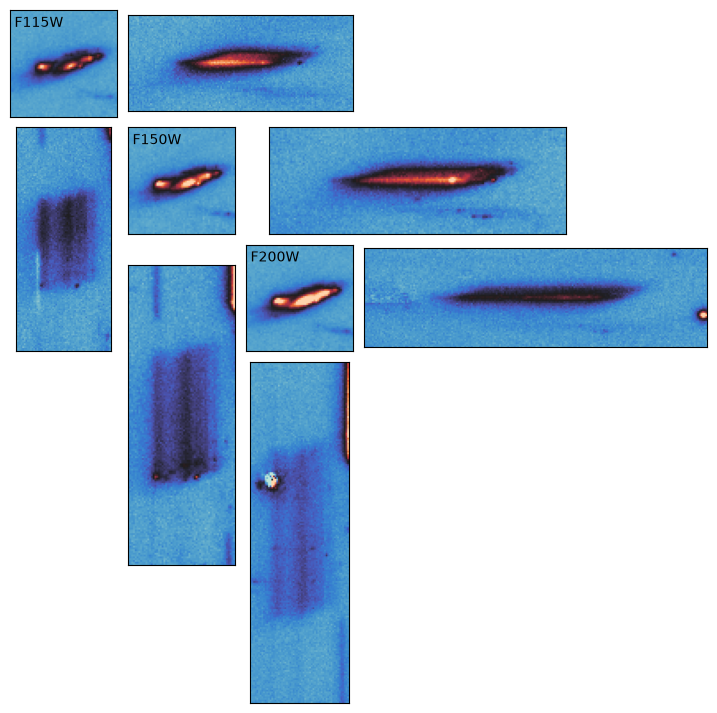

In [5]:
stk = {'GR150C':{'F115W' : [],'F150W' : [],'F200W' : []},
        'GR150R':{'F115W' : [],'F150W' : [],'F200W' : []}}

for p in gx.obj.beams:
    for b in gx.obj.beams[p]:
        stk[b.meta['filter']][p].append(b.spec['sci'] - b.spec['contam'])

gs = GridSpec(6,6, hspace = 0.1, wspace=0.1)

plt.figure(figsize = [9,9])

ax0 = plt.subplot(gs[0,0])
ax1 = plt.subplot(gs[0,1:3])
ax2 = plt.subplot(gs[1:3,0])

ax3 = plt.subplot(gs[1,1])
ax4 = plt.subplot(gs[1,2:5])
ax5 = plt.subplot(gs[2:5,1])

ax6 = plt.subplot(gs[2,2])
ax7 = plt.subplot(gs[2,3:6])
ax8 = plt.subplot(gs[3:6,2])

ax0.imshow(gx.obj.beams['F115W'][0].direct['sci'], cmap = 'icefire', vmin = -0.01, vmax = 0.06)
ax1.imshow(np.median(stk['GR150C']['F115W'], 0), cmap = 'icefire', vmin = -0.1, vmax = 0.5)
ax2.imshow(np.median(stk['GR150R']['F115W'], 0), cmap = 'icefire', vmin = -0.1, vmax = 0.5)

ax3.imshow(gx.obj.beams['F150W'][0].direct['sci'], cmap = 'icefire', vmin = -0.01, vmax = 0.06)
ax4.imshow(np.median(stk['GR150C']['F150W'], 0), cmap = 'icefire', vmin = -0.1, vmax = 0.5)
ax5.imshow(np.median(stk['GR150R']['F150W'], 0), cmap = 'icefire', vmin = -0.1, vmax = 0.5)

ax6.imshow(gx.obj.beams['F200W'][0].direct['sci'], cmap = 'icefire', vmin = -0.01, vmax = 0.06)
ax7.imshow(np.median(stk['GR150C']['F200W'], 0), cmap = 'icefire', vmin = -0.1, vmax = 0.5)
ax8.imshow(np.median(stk['GR150R']['F200W'], 0), cmap = 'icefire', vmin = -0.1, vmax = 0.5)

for ax in [ax0, ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8]:
    ax.set_xticks([])
    ax.set_yticks([])

ax0.text(2,9,'F115W')
ax3.text(2,9,'F150W')
ax6.text(2,9,'F200W')


#### Standard configuration scripts


In [6]:
# gx.standard_config(500)      # runs all of these functions; should only be run on initial extraction

#load images
gx.load_images('reference')    # loads in images, in this case PSF-matched HST and NIRCam images

# ---  only needs to be run when loading in galaxy ---
gx.reset_seg()
gx.reseg()

#initialize spectra
gx.single_seg()                 # Changes segmentation map to omit other galaxies and sets galaxy id to 1
gx.reseg()                      # propogates seg map
gx.prepare_foward_model()       # saves out forward modeling geometry
gx.gen_mask()                   # makes fit mask
gx.build_flats()                # makes flat arrays that are used when fitting

#remove_backgrounds
# gx.background_subtract_spec() # removes background in each beam, since this is a loaded beam it's already been run
# gx.build_flats()

#correct trace
# gx.correct_trace()             # finds and corrects for the trace offset (already done)

#color segment
gx.prepare_segmentation()        # creates color maps to prepare grouping
gx.reset_seg()                   # resets segmentation so the galaxy reflects its original id, this needs to be run (along with reseg) before .segment
gx.reseg()
gx.segment(limit = 30)           # segments the galaxy into multiple regions using a nearest neighbors approach
gx.reseg()

#get phot
gx.extract_phot()                # gets the photometric values of each region; should be rerun if you update the number of regions

#### Example of a fit mask, this is only part of the beam that will be fit

([], [])

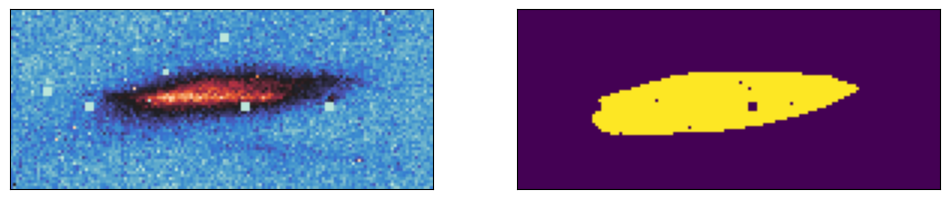

In [7]:
plt.figure(figsize = [12,5])

plt.subplot(121)
plt.imshow(gx.obj.beams['F115W'][0].spec['sci'], cmap = 'icefire', vmin = -0.1, vmax = 0.5)
plt.xticks([])
plt.yticks([])


plt.subplot(122)
plt.imshow(gx.obj.beams['F115W'][0].mask,  )
plt.xticks([])
plt.yticks([])

#### Plot of the current segmentation map

7

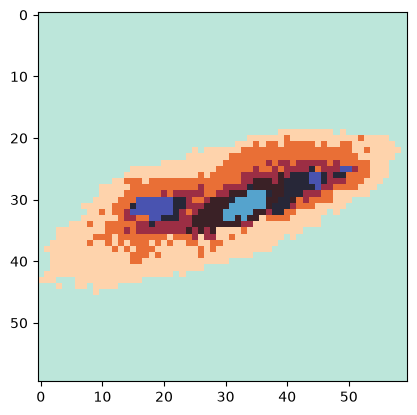

In [8]:
gx.segment(method='color', limit=30)
plt.imshow(gx.Nseg, cmap = 'icefire')
gx.nregions

# Contamination Subtraction

## Identify Contaminators

This will identify any galaxies that could potentially contaminate the spectra. If a candidate is found, it is first checked against the flux table. If it passes that check, a geometric check is then performed to determine whether the galaxy actually contaminates the beam. If it does, the galaxy is added to the contamination dictionary. The beam provided has its contamination already subtracted. 


In [9]:
# from sleuth.contam import extract_contam,geometric_check,id_contam_candidate

# contam_list = {'GR150R' :{'F115W':{'+1':[], '0':[], '+2':[], '+3':[], '-1':[]},
#                      'F150W':{'+1':[], '0':[], '+2':[], '+3':[], '-1':[]},
#                      'F200W':{'+1':[], '0':[], '+2':[], '+3':[], '-1':[]}},
#               'GR150C' :{'F115W':{'+1':[], '0':[], '+2':[], '+3':[], '-1':[]},
#                      'F150W':{'+1':[], '0':[], '+2':[], '+3':[], '-1':[]},
#                      'F200W':{'+1':[], '0':[], '+2':[], '+3':[], '-1':[]}},}
# sz = gx.obj.sz
# pad = gx.obj.pad

# contam_cache = {}
# seg = field.exposures[0]['seg']
# final_candidates = set()

# for pupil in ['F115W', 'F150W', 'F200W']:
#     seen_grisms = []
#     for bid, MB in enumerate(gx.obj.beams[pupil]):
#         grism = MB.meta['filter']

#         if grism in seen_grisms:
#             continue

#         seen_grisms.append(grism)

#         ty1,ty2,tx1,tx2 = MB.cutout_limits

#         overlap_map = np.zeros([3648,3648])
#         overlap_map[ty1:ty2,tx1:tx2] = MB.mask

#         for i, order in enumerate(['+1', '0', '+2', '+3', '-1']):
#             candidates = id_contam_candidate(field, MB, flux_table, limits, gx.obj.gid,
#                                              pupil, order, pad, sz,)
#             for cid in candidates:
#                 if not (cid, order) in contam_cache:
#                     print(f"    --> extracting {(cid,order)}")
#                     cx = extract_contam(field, seg, cid, order)

#                 else:
#                     cx = contam_cache[(cid, order)] 

#                 outid = geometric_check(cx, pupil, bid, MB.cutout_limits, overlap_map)  

#                 if outid > 0:
#                     contam_list[grism][pupil][order].append(cid)
#                     final_candidates.add((cid, order))
#                     contam_cache[(cid, order)] = cx

## Model Out Contamination

This will take the galaxies in the contamination dictionary and model their flux using a simple approach. If desired, more advanced techniques and spectral templates can be used, but for most sources, a simple flat spectrum with a fixed flux value is sufficient.

In [10]:
# from sleuth.fitting_utils import asymmetric_loss, shift_rotate

# for pupil in gx.obj.beams:
#     for grism in ['GR150R', 'GR150C']:
#         has_contam = False
#         contaminators = set()
#         for order, item in contam_list[grism][pupil].items():
#             if len(item) > 0:
#                 has_contam = True
#                 for cid in item:
#                     contaminators.add((cid,order))

#         if has_contam:
#             for bid, MB in enumerate(gx.obj.beams[pupil]):
#                 if MB.meta['filter'] == grism:
#                     contam_field = np.zeros([3648,3648])
            
#                     flux = np.sum(gx.images[pupil]['sci'][gx.obj.images['seg'] > 0])
#                     total_flux = np.sum(MB.direct['sci'][MB.direct['seg']>0])
                    
#                     model_t = gx.forward_model(MB,MB.direct['sci'], [MB.spec['lam']*1e4, 
#                             flux*np.ones_like(MB.spec['lam'])/total_flux])

#                     if not MB.meta['corrected']:
#                         result = minimize(asymmetric_loss, x0=[0, 0, 0,1],args=(MB.spec['sci'], model_t, 
#                                 MB.spec['err'], MB.mask),method='Powell',
#                                 bounds=[(-2, 2),(-2, 2),(-1, 1),(0.95, 1.1)],
#                                 options={'xtol': 1e-5, 'ftol': 1e-5, 'maxiter': 1000, 'disp': False,})
    
#                         dx, dy, theta, amp = result.x
#                         model_t = shift_rotate( np.asarray(model_t), dx=dx, dy=dy, theta_deg=theta)*amp

#                     ty1,ty2,tx1,tx2 = MB.cutout_limits

#                     contam_field[ty1:ty2,tx1:tx2] += model_t

#                     for CID in contaminators:
#                         cx = contam_cache[(CID)]

#                         CB = cx.obj.beams[pupil][bid]
#                         y1,y2,x1,x2 = CB.cutout_limits

#                         CB.spec['contam'] = contam_field[y1:y2,x1:x2] 
                        
#                         flux = np.sum(cx.images[pupil]['sci'][cx.obj.images['seg'] > 0])
#                         total_flux = np.sum(CB.direct['sci'][CB.direct['seg']>0])
                        
#                         mdl = cx.forward_model(CB,CB.direct['sci'], [CB.spec['lam']*1e4, 
#                                 flux*np.ones_like(CB.spec['lam'])/total_flux])

#                         if not CB.meta['corrected']:
#                             maxamp = 1.1
#                             if order == '0':
#                                 maxamp = 2.0
                            
#                             result = minimize(asymmetric_loss, x0=[0, 0, 0,1],args=(CB.spec['sci'] - CB.spec['contam'], mdl, 
#                                     CB.spec['err'], CB.mask),method='Powell',
#                                     bounds=[(-2, 2),(-2, 2),(-1, 1),(0.95, maxamp)],
#                                     options={'xtol': 1e-5, 'ftol': 1e-5, 'maxiter': 1000, 'disp': False,})
        
#                             dx, dy, theta, amp = result.x
#                             mdl = shift_rotate( np.asarray(mdl), dx=dx, dy=dy, theta_deg=theta)*amp

    
#                         contam_field[y1:y2,x1:x2] += mdl

#                     MB.spec['contam'] = contam_field[ty1:ty2,tx1:tx2] - model_t

## Color - Color Nearest Neighbors Segmentation

#### The cutouts of galaxy being fit

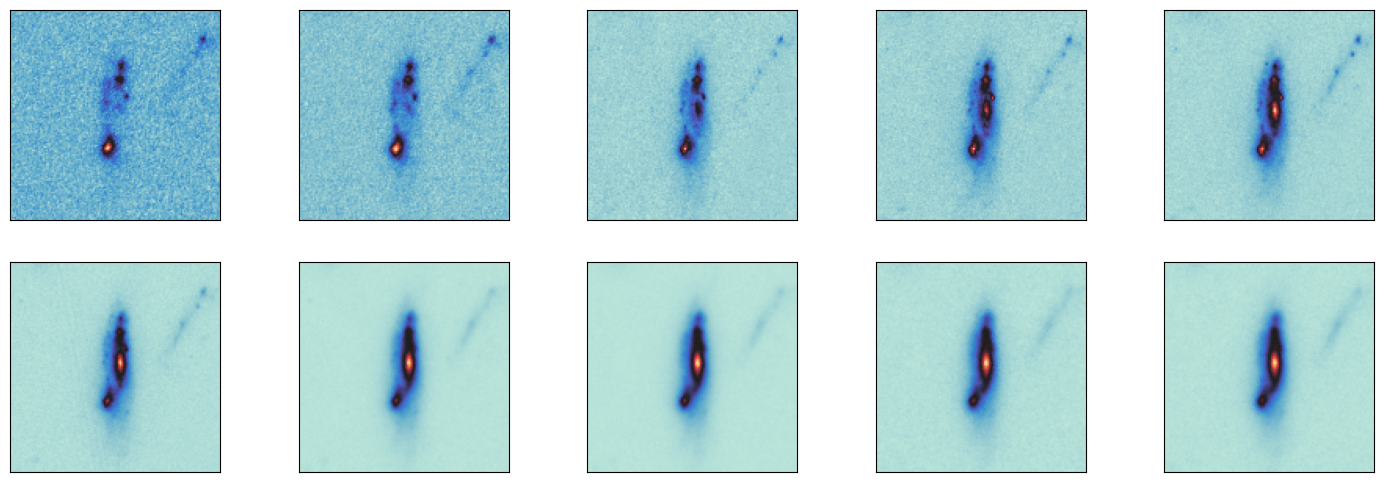

In [11]:
gs = GridSpec(2,5)
plt.figure(figsize = [18,6])

for i,f in enumerate(['F435W', 'F606W', 'F090W', 'F115W', 'F150W', 'F200W', 'F277W', 'F356W', 'F410M', 'F444W']):
    plt.subplot(gs[i])
    plt.imshow(gx.images[f]['sci'], cmap = 'icefire')
    plt.xticks([])
    plt.yticks([])



#### If you want, you can resegment the galaxy using different signal-to-noise thresholds. Just **make sure to re-extract the photometry afterward**

Fewer regions will result in a faster runtime, but using too few regions can lead to a poor continuum model. Conversely, using too many regions can significantly increase the runtime.

The limit set here, 30, produces 7 regions. For a galaxy this clumpy and complex, that isn’t enough to adequately model the continuum. A signal-to-noise threshold of 10 provides a better fit, but will take longer to run.

7

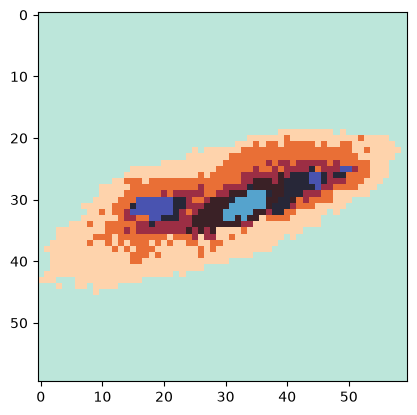

In [12]:
gx.reset_seg()
gx.reseg()

gx.segment(method='color', limit=30)
plt.imshow(gx.Nseg, cmap = 'icefire')
gx.nregions

In [13]:
gx.reseg()

In [14]:
gx.extract_phot()

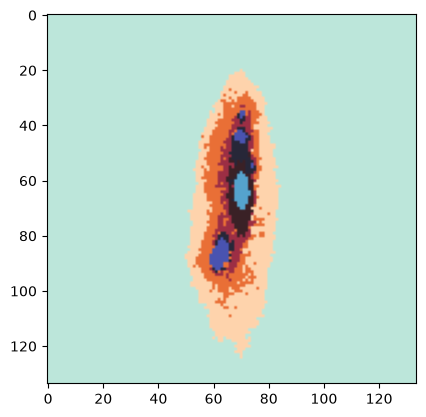

In [15]:
plt.imshow(gx.nircam_Nseg, cmap = 'icefire')

## Spatially Resolved Photometry

#### Here you can see the variety of SEDs across different regions of the galaxy.

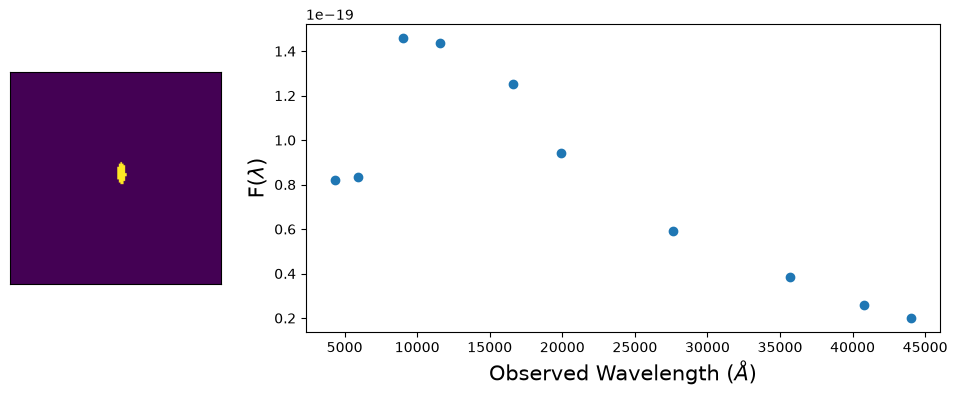

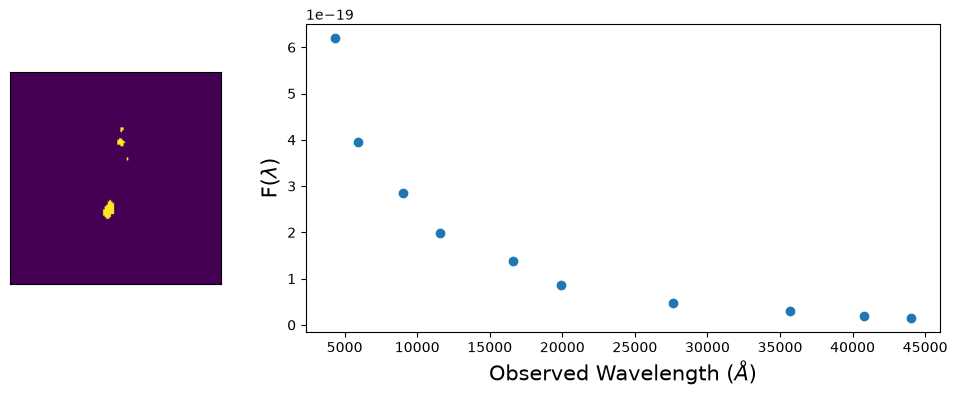

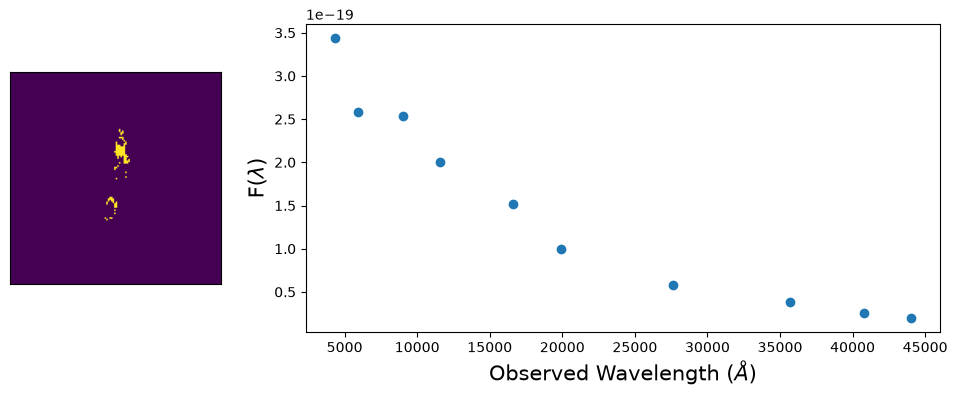

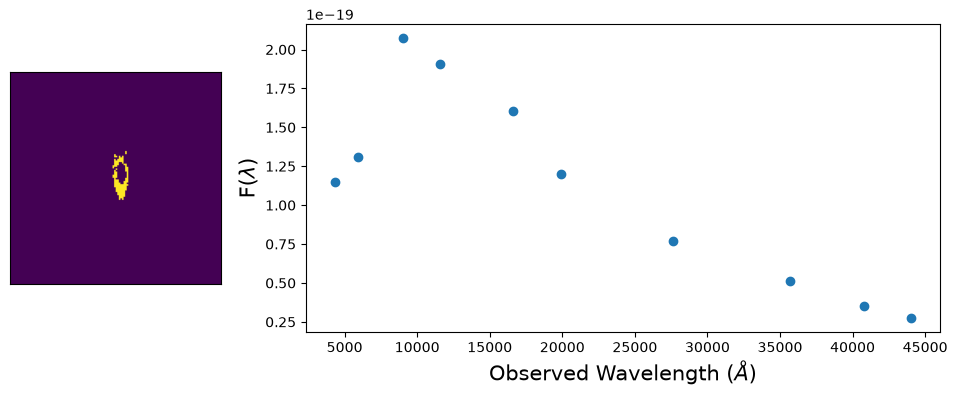

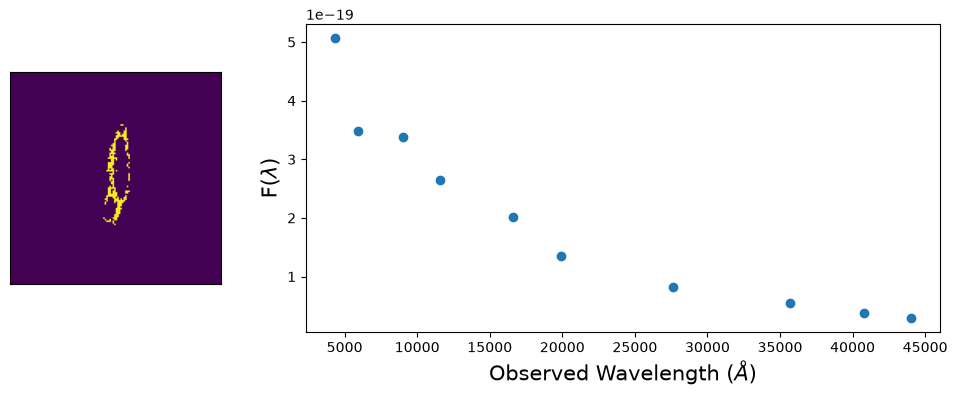

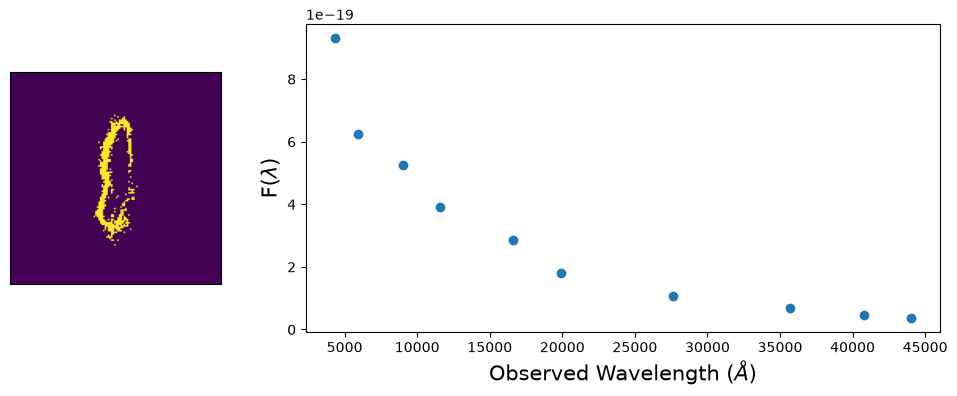

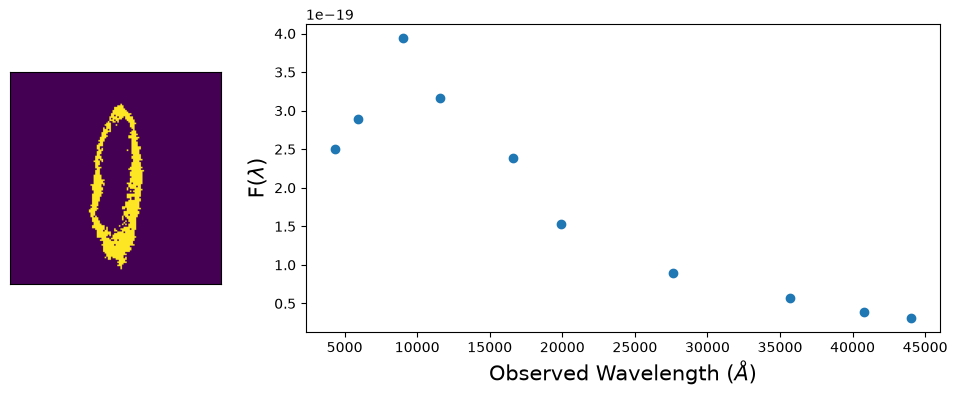

In [16]:

for sid in gx.seg_ids:
    gs = GridSpec(1,2, width_ratios=[1,3])
    plt.figure(figsize=[12,4])
    plt.subplot(gs[0])
    plt.imshow(gx.nircam_Nseg == sid)
    plt.xticks([])
    plt.yticks([])

    
    plt.subplot(gs[1])
    plt.scatter(gx.phot.photom_pivot, gx.phot.photom_flam[sid])

    plt.xlabel(r'Observed Wavelength ($\AA$)', fontsize = 15)
    plt.ylabel(r'F($\lambda$)', fontsize = 15)
    

## Generate Template Set

Here I’m building the template set that will be used to fit the spectra. Right now, it’s set up to use my templates, but I still need to generalize it so that any template set can be used.

There are ways to work around this in the meantime: you can use any set of continuum templates, but the line templates currently expect them to follow my specific format.


In [17]:
specz = 1.051


Tdict = TemplateLibrary(gx.phot, specz, '../../../data/models/', '../../../data/lines/')

Tdict.load_continuum()

Tdict.load_lines(['Ha',  'OIII', 'SII', 'SIII', 'Hb'])

TG = {}

for sid in gx.seg_ids:
    templates, coeffs = Tdict.select_templates(
        phot_flux=gx.phot.photom_flam[sid],
        phot_err=gx.phot.photom_eflam[sid],
        n_keep=10)

    TG[sid] = {}
    for i,t in enumerate(templates):
        TG[sid][i] = Grism_template(wave = t['wave'],flux=t['flux'])

add_lines_to_template(TG, ['Ha', 'SII', 'SIII'],  '../../../data/lines/')

## Extract Emission Line Map

In [18]:
gx.ELMap_extract('F150W', TG, specz, ['Ha'], 'demo_out.h5py', '../../../data/lines')

! 3037 points were outside the output image.
! 3037 points were outside the output image.
! 3020 points were outside the output image.
! 3020 points were outside the output image.
! 3038 points were outside the output image.
! 3038 points were outside the output image.
! 3021 points were outside the output image.
! 3021 points were outside the output image.
! 3020 points were outside the output image.
! 3020 points were outside the output image.
! 3020 points were outside the output image.
! 3020 points were outside the output image.
! 3038 points were outside the output image.
! 3038 points were outside the output image.
! 3038 points were outside the output image.
! 3038 points were outside the output image.
! 3020 points were outside the output image.
! 3020 points were outside the output image.
! 3037 points were outside the output image.
! 3037 points were outside the output image.
! 3038 points were outside the output image.
! 3038 points were outside the output image.
! 3020 poi

Saving Ha


In [19]:
from sleuth.linemaps import load_sleuth_maps
resultM = load_sleuth_maps("demo_out.h5py", obj_id="429", lines=["Ha"])


Set OBSGEO-B to    28.678231 from OBSGEO-[XYZ].
Set OBSGEO-H to 1266059043.066 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


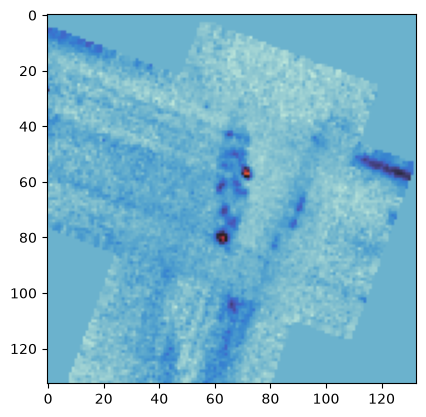

In [20]:
plt.imshow(resultM["maps"]["Ha"]['line'], cmap = 'icefire', vmin = -.05, vmax = .4)

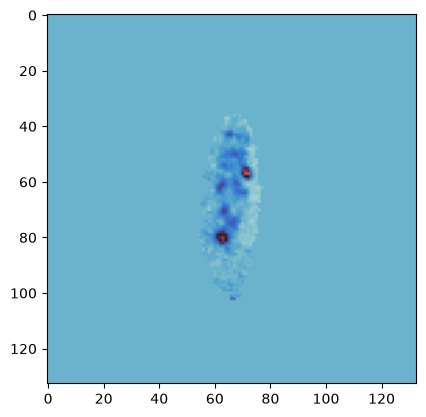

In [21]:
plt.imshow(resultM["maps"]["Ha"]['line'] * (resultM["maps"]["Ha"]['seg']>0), cmap = 'icefire', vmin = -.05, vmax = .4)